# Δημιουργία απλού κβαντικού κυκλώματος
Σκοπός είναι να φτιάξουμε ένα απλό κύκλωμα με qubits και κβαντικές πύλες που θα μπορούν να αλλάζουν την κατάστασή τους, με καθοδήγηση βήμα προς βήμα.
### Εγκατάσταση των απαραίτητων βιβλιοθηκών
Θα χρειαστεί να εγκαταστήσουμε ορισμένες βιβλιοθήκες. Η qiskit είναι η βασική βιβλιοθήκη της Python που χρησιμοποιείται για να σχεδιάζουμε, να προσομοιώνουμε και να εκτελούμε κβαντικούς αλγορίθμους σε κβαντικούς υπολογιστές. Η matplotlib θα χρησιμοποιηθεί μόνο για τη γραφική αναπαράσταση του qubit πάνω στη σφαίρα Bloch.



In [8]:
from qiskit import *
from qiskit.quantum_info import Pauli, Statevector
from qiskit.visualization.bloch import Bloch
import matplotlib.pyplot as plt

### Δημιουργία του κβαντικού κυκλώματος
Εδώ θα χρησιμοποιήσουμε την πρώτη μας εντολή:

In [11]:
qr = QuantumRegister(1, 'q')
qc = QuantumCircuit(qr)

Η πρώτη εντολή δημιουργεί ένα μητρώο, το οποίο αποθηκεύει όλα τα qubits. Το 'q' δηλώνει το όνομα του μητρώου (δηλαδή το όνομα που θα εμφανίζεται μπροστά από τα qubits στο διάγραμμα του κυκλώματος), ενώ το πρώτο όρισμα της συνάρτησης δηλώνει το πλήθος των qubits που θέλουμε να έχει το κύκλωμα. Στην περίπτωσή μας, ξεκινάμε με 1 μόνο qubit.
Η δεύτερη εντολή παίρνει το μητρώο και το μετατρέπει σε κβαντικό κύκλωμα. Αυτές οι δύο εντολές είναι απαραίτητες κάθε φορά που θέλουμε να φτιάξουμε ένα κβαντικό κύκλωμα.
Εάν είχα παραπάνω qubits και ήθελα access σε αυτά, θα χρησιμοποιούσα απαρίθμηση πίνακα:

$qr[0]\\
qr[1]$ κτλ

In [16]:
qc.initialize([0,1], qr[0])

Η εντολή αυτή αρχικοποιεί το qubit qr[0], δηλαδή το πρώτο και μοναδικό μας qubit, στην κατάσταση που δίνεται από το διάνυσμα [0,1], δηλαδή την κατάσταση |1>.

In [13]:
psi1 = Statevector(qc)


Εδώ αποθηκεύσαμε την πρώτη μας κβαντική κατάσταση, την $\ket{\Psi _1} = \ket{1}$. Το Qiskit υπολογίζει την κβαντική κατάσταση που προκύπτει από τις εντολές του κυκλώματος μέχρι εκείνο το σημείο και δημιουργεί ένα αντικείμενο τύπου Statevector από το κύκλωμα qc. Τώρα έχουμε ένα αντικείμενο που περιέχει τα πλάτη πιθανότητας της κατάστασης και μπορούμε να κάνουμε υπολογισμούς πάνω σε αυτά, ή να τα αναπαριστούμε γραφικά.

### Εφαρμογή κβαντικών πυλών
Θα εφαρμόσουμε τώρα την πρώτη μας κβαντική πύλη πάνω στο qubit, την κβαντική πύλη Χ. Η πύλη αυτή περιστρέφει το qubit γύρω από τον άξονα x της σφαίρας Bloch κατά 180, αντιστρέφοντας την κατάσταση του qubit. Είναι η κβαντική πύλη ΝΟΤ.

In [17]:
# Εφαρμόζει την πύλη Χ στο qubit qr[0], δηλαδή το πρώτο του μητρώου qr.
qc.x(qr[0])
psi2 = Statevector(qc) # Αποθηκεύουμε τη νέα κατάσταση του κυκλώματος

### Μετατροπή της κβαντικής κατάστασης σε συντεταγμένες Bloch
Σκοπός της παρακάτω συνάρτησης είναι να υπολογίσει τις τρεις Καρτεσιανές συντεταγμένες του διανύσματος Bloch για μια κβαντική κατάσταση. Η συνάρτηση δέχεται σαν όρισμα μια κβαντική κατάσταση (την $\ket{\Psi _1}$ ή την $\ket{\Psi _2}$ που δημιουργήσαμε). Έπειτα, υπολογίζει τις μέσες τιμές των τελεστών X, Y και Z για τη συγκεκριμένη κατάσταση, χωρίς όμως να τις εφαρμόζει, αλλάζοντας την κατάσταση. Αυτό θα μας δώσει τις συντεταγμένες (x,y,z) του διανύσματος στη σφαίρα Bloch για την κατάσταση $\ket{\Psi}$ που βάλαμε ως όρισμα. Είναι δηλαδή:

$(x,y,z) = (\braket{X},\braket{Y},\braket{Z})$

όπου τα $\braket{X},\braket{Y},\braket{Z}$ είναι οι μέσες τιμές των τελεστών Pauli (οι τελεστές Χ, Υ, Ζ ονομάζονται και τελεστές Pauli)

In [18]:
def bloch_coords(state):
    return [state.expectation_value(Pauli(axis)).real
            for axis in ("X", "Y", "Z")]

### Απεικόνιση στη σφαίρα Bloch
Θα δημιουργήσουμε τώρα ένα αντικείμενο τύπου σφαίρα, στο οποίο θα προσθέσουμε τα διανύσματα των καταστάσεων $\ket{\Psi _1}$ και $\ket{\Psi _2}$. Το πρώτο διάνυσμα θα είναι κόκκινο (πριν την εφαρμογή της πύλης Χ) και το δεύτερο θα είναι μπλε (μετά την εφαρμογή της Χ). Τα χρώματα αντιστοιχίζονται στη σειρά με την οποία προσθέτουμε τα διανύσματα, οπότε πρέπει να προσθέσουμε πρώτα την $\ket{\Psi _1}$ και έπειτα την $\ket{\Psi _2}$.

In [19]:
sphere = Bloch()
sphere.vector_color = ["red", "blue"]
# Εδώ προσθέτουμε τα διανύσματα των καταστάσεων στη σφαίρα, πρώτα την |Ψ1> και έπειτα την |Ψ2>
sphere.add_vectors(bloch_coords(psi1))
sphere.add_vectors(bloch_coords(psi2))

Χρησιμοποιούμε τέλος δύο ακόμα εντολές, και η σφαίρα Bloch εμφανίζεται στην οθόνη. Τι περιμένουμε; Η αρχική μας κατάσταση ήταν η $\ket{\Psi _1} = \ket{1}$, άρα περιμένουμε το κόκκινο διάνυσμα να κοιτάζει κάτω, στον νότιο πόλο της σφαίρας. Μετά την αντιστροφή από την πύλη Χ, βρισκόμαστε στην κατάστση $\ket{\Psi _2} = \ket{0}$, οπότε το μπλε διάνυσμα θα κοιτάζει στον βόρειο πόλο της σφαίρας:

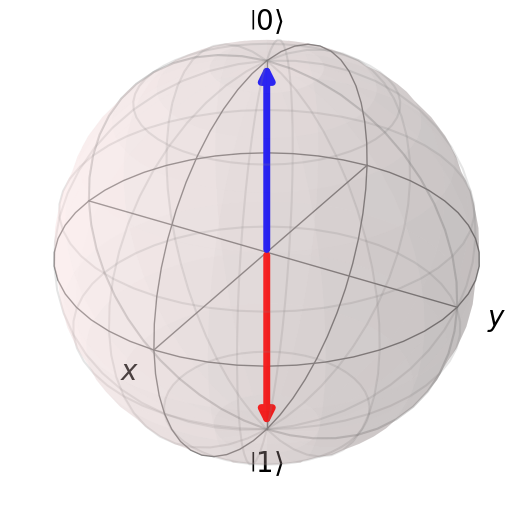

In [20]:
sphere.render() # Δημιουργεί την οπτική αναπαράσταση της σφαίρας Bloch με τα διανύσματα που έχουμε προσθέσει
plt.show() # Εμφανίζει το γράφημα στην οθόνη